In [1]:
# Import core libraries
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn model selection and validation
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate

# Preprocessing and pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Traditional Machine Learning models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Set visualization style
%matplotlib inline
sns.set_theme(style='whitegrid')

print("All libraries imported successfully!")


C:\Users\vhres\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\vhres\AppData\Local\Temp\matplotlib-vb95_9rh because there was an issue with the default path (C:\Users\vhres\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


All libraries imported successfully!


In [2]:
# Resolve dataset file path
if os.path.exists('data/processed/student_model_data.csv'):
    file_path = 'data/processed/student_model_data.csv'
elif os.path.exists('../data/processed/student_model_data.csv'):
    file_path = '../data/processed/student_model_data.csv'
else:
    file_path = 'D:/STD_SUPPORT_project/data/processed/student_model_data.csv'

print(f"Loading modeling dataset from: {file_path}")
df = pd.read_csv(file_path)

print(f"Dataset Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(5)


Loading modeling dataset from: ../data/processed/student_model_data.csv
Dataset Dimensions: 27,373 rows, 20 columns


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,disability,num_of_prev_attempts,studied_credits,date_registration,total_clicks,active_days,unique_sites,pre_course_clicks,early_assessments_submitted,early_avg_score,has_early_submission,target
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,N,0,240,-159.0,424.0,10.0,26.0,98.0,1.0,78.0,1,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,N,0,60,-53.0,618.0,19.0,34.0,215.0,1.0,70.0,1,0
2,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,N,0,60,-52.0,540.0,24.0,32.0,169.0,1.0,72.0,1,0
3,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,N,0,60,-176.0,567.0,24.0,34.0,295.0,1.0,69.0,1,0
4,AAA,2013J,38053,M,Wales,A Level or Equivalent,80-90%,35-55,N,0,60,-110.0,730.0,33.0,30.0,277.0,1.0,79.0,1,0


In [3]:
# Inspect column data types and missing values
print("=== Column Types and Non-Null Counts ===")
df.info()


=== Column Types and Non-Null Counts ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   code_module                  27373 non-null  object 
 1   code_presentation            27373 non-null  object 
 2   id_student                   27373 non-null  int64  
 3   gender                       27373 non-null  object 
 4   region                       27373 non-null  object 
 5   highest_education            27373 non-null  object 
 6   imd_band                     26347 non-null  object 
 7   age_band                     27373 non-null  object 
 8   disability                   27373 non-null  object 
 9   num_of_prev_attempts         27373 non-null  int64  
 10  studied_credits              27373 non-null  int64  
 11  date_registration            27366 non-null  float64
 12  total_clicks                 2737

In [4]:
# Check target distribution
target_counts = df['target'].value_counts()
target_percents = (df['target'].value_counts(normalize=True) * 100).round(2)

target_summary = pd.DataFrame({
    'Target Class': [0, 1],
    'Outcome Description': ['Not At Risk (Pass / Distinction)', 'At Risk (Fail / Post-Day 30 Withdrawn)'],
    'Enrollment Count': [target_counts[0], target_counts[1]],
    'Percentage (%)': [target_percents[0], target_percents[1]]
})
target_summary


,Target Class,Outcome Description,Enrollment Count,Percentage (%)
0,0,Not At Risk (Pass / Distinction),15385,56.21
1,1,At Risk (Fail / Post-Day 30 Withdrawn),11988,43.79


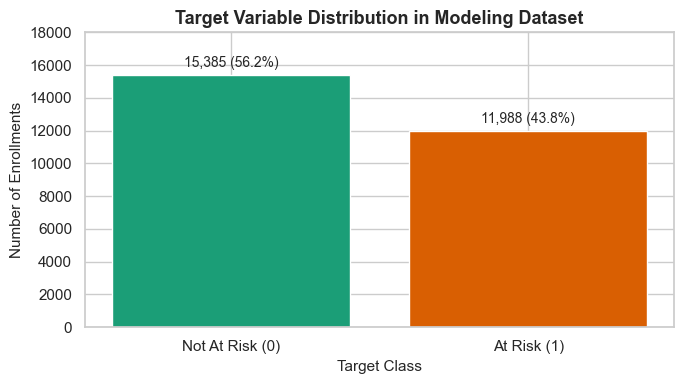

In [5]:
# Visualize the target distribution
plt.figure(figsize=(7, 4))
bars = plt.bar(['Not At Risk (0)', 'At Risk (1)'], [target_counts[0], target_counts[1]], color=['#1b9e77', '#d95f02'])
plt.title('Target Variable Distribution in Modeling Dataset', fontsize=13, fontweight='bold')
plt.xlabel('Target Class', fontsize=11)
plt.ylabel('Number of Enrollments', fontsize=11)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., height + 300, f'{int(height):,} ({height / len(df) * 100:.1f}%)', ha='center', va='bottom', fontsize=10)

plt.ylim(0, 18000)
plt.tight_layout()
plt.show()


In [6]:
# Separate target vector, group identifiers, and feature matrix
y = df['target']
groups = df['id_student']

# Exclude id_student and target from input features
X = df.drop(columns=['id_student', 'target'])

# Identify categorical and numerical column names
cat_cols = [
    'code_module', 
    'code_presentation', 
    'gender', 
    'region', 
    'highest_education', 
    'imd_band', 
    'age_band', 
    'disability'
]

num_cols = [
    'num_of_prev_attempts', 
    'studied_credits', 
    'date_registration', 
    'total_clicks', 
    'active_days', 
    'unique_sites', 
    'pre_course_clicks', 
    'early_assessments_submitted', 
    'early_avg_score', 
    'has_early_submission'
]

print(f"Total input features: {X.shape[1]}")
print(f"- Categorical features ({len(cat_cols)}): {cat_cols}")
print(f"- Numerical features ({len(num_cols)}): {num_cols}")


Total input features: 18
- Categorical features (8): ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']
- Numerical features (10): ['num_of_prev_attempts', 'studied_credits', 'date_registration', 'total_clicks', 'active_days', 'unique_sites', 'pre_course_clicks', 'early_assessments_submitted', 'early_avg_score', 'has_early_submission']


In [7]:
# Perform group-aware train/test split (80% train / 20% test)
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("=== Train / Test Split Summary ===")
print(f"Training set: {X_train.shape[0]:,} rows ({X_train.shape[0] / len(X) * 100:.1f}%)")
print(f"Testing set:  {X_test.shape[0]:,} rows ({X_test.shape[0] / len(X) * 100:.1f}%)")


=== Train / Test Split Summary ===
Training set: 21,911 rows (80.0%)
Testing set:  5,462 rows (20.0%)


In [8]:
# Verify zero student overlap between training and testing sets
train_students = set(groups_train)
test_students = set(groups_test)
student_overlap = train_students.intersection(test_students)

print("=== Student Leakage Verification ===")
print(f"Unique students in training set: {len(train_students):,}")
print(f"Unique students in testing set:  {len(test_students):,}")
print(f"Number of overlapping students:  {len(student_overlap)}")
print(f"Is student-level leakage completely prevented? {len(student_overlap) == 0}")


=== Student Leakage Verification ===
Unique students in training set: 19,768
Unique students in testing set:  4,942
Number of overlapping students:  0
Is student-level leakage completely prevented? True


In [9]:
# 1. Numerical preprocessing pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Categorical preprocessing pipeline
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. Combine pipelines using ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

print("Preprocessing pipeline built successfully!")
print(preprocessor)


Preprocessing pipeline built successfully!
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['num_of_prev_attempts', 'studied_credits',
                                  'date_registration', 'total_clicks',
                                  'active_days', 'unique_sites',
                                  'pre_course_clicks',
                                  'early_assessments_submitted',
                                  'early_avg_score', 'has_early_submission']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Missing',
                                                                strategy='constant')),
    

In [10]:
# Define the 5 traditional machine learning models
models = {
    'Dummy (Baseline)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=15, n_jobs=-1)
}

print("Models initialized:")
for name in models:
    print(f"- {name}")


Models initialized:
- Dummy (Baseline)
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors


In [11]:
# Setup 5-fold GroupKFold cross-validator
gkf = GroupKFold(n_splits=5)

# Define evaluation scoring dictionary
scoring = {
    'recall': 'recall',
    'precision': 'precision',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

cv_results_list = []

print("Running 5-fold GroupKFold cross-validation on training set...")

for name, model in models.items():
    start_time = time.time()
    
    # Construct complete pipeline: Preprocessing + Model
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Run cross-validation with student group constraints
    cv_output = cross_validate(
        pipe,
        X_train,
        y_train,
        groups=groups_train,
        cv=gkf,
        scoring=scoring,
        n_jobs=1
    )
    
    elapsed = time.time() - start_time
    
    cv_results_list.append({
        'Model': name,
        'Recall': cv_output['test_recall'].mean(),
        'Precision': cv_output['test_precision'].mean(),
        'F1-Score': cv_output['test_f1'].mean(),
        'ROC-AUC': cv_output['test_roc_auc'].mean(),
        'PR-AUC': cv_output['test_pr_auc'].mean(),
        'Fit Time (s)': round(elapsed, 2)
    })
    print(f"- {name}: completed in {elapsed:.1f}s")

# Compile into comparison DataFrame
cv_comparison = pd.DataFrame(cv_results_list)
cv_comparison = cv_comparison.sort_values(by='Recall', ascending=False).reset_index(drop=True)
cv_comparison


Running 5-fold GroupKFold cross-validation on training set...


C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


- Dummy (Baseline): completed in 0.7s


- Logistic Regression: completed in 1.0s


- Decision Tree: completed in 1.2s


- Random Forest: completed in 3.0s


C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
  File "C:\Users\vhres\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\vhre

- K-Nearest Neighbors: completed in 4.5s


,Model,Recall,Precision,F1-Score,ROC-AUC,PR-AUC,Fit Time (s)
0,Logistic Regression,0.585624,0.704097,0.639399,0.771687,0.747880,1.04
1,Random Forest,0.552672,0.725236,0.627263,0.775967,0.751477,3.02
2,K-Nearest Neighbors,0.550692,0.692081,0.613319,0.748203,0.701839,4.52
3,Decision Tree,0.525242,0.706218,0.601903,0.748095,0.708005,1.22
4,Dummy (Baseline),0.000000,0.000000,0.000000,0.500000,0.439004,0.74


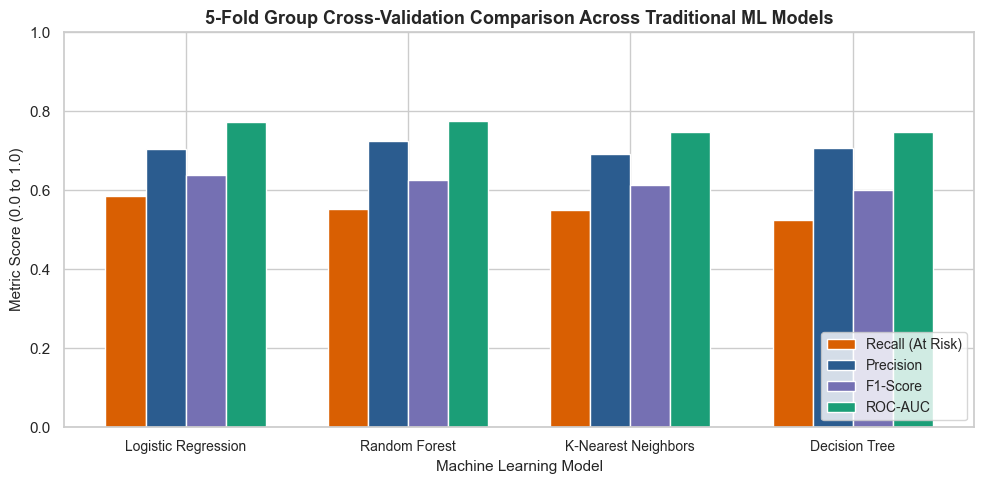

In [12]:
# Visualize Model Comparison across Metrics
plt.figure(figsize=(10, 5))
plot_data = cv_comparison[cv_comparison['Model'] != 'Dummy (Baseline)'].copy()

bar_width = 0.18
x = np.arange(len(plot_data))

plt.bar(x - 1.5*bar_width, plot_data['Recall'], width=bar_width, label='Recall (At Risk)', color='#d95f02')
plt.bar(x - 0.5*bar_width, plot_data['Precision'], width=bar_width, label='Precision', color='#2b5c8f')
plt.bar(x + 0.5*bar_width, plot_data['F1-Score'], width=bar_width, label='F1-Score', color='#7570b3')
plt.bar(x + 1.5*bar_width, plot_data['ROC-AUC'], width=bar_width, label='ROC-AUC', color='#1b9e77')

plt.title('5-Fold Group Cross-Validation Comparison Across Traditional ML Models', fontsize=13, fontweight='bold')
plt.xlabel('Machine Learning Model', fontsize=11)
plt.ylabel('Metric Score (0.0 to 1.0)', fontsize=11)
plt.xticks(x, plot_data['Model'], fontsize=10)
plt.ylim(0.0, 1.0)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


In [13]:
# Fit the selected Logistic Regression pipeline on the full training data
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

final_pipeline.fit(X_train, y_train)

# Generate predictions and probabilities on the test set
y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]

print("Model successfully fitted and evaluated on test set!")


Model successfully fitted and evaluated on test set!


In [14]:
# Display Classification Report
print("=== Classification Report (Held-Out Test Set) ===")
print(classification_report(y_test, y_test_pred, target_names=['Not At Risk (0)', 'At Risk (1)'], digits=4))


=== Classification Report (Held-Out Test Set) ===
                 precision    recall  f1-score   support

Not At Risk (0)     0.7181    0.8054    0.7592      3093
    At Risk (1)     0.6979    0.5872    0.6378      2369

       accuracy                         0.7107      5462
      macro avg     0.7080    0.6963    0.6985      5462
   weighted avg     0.7093    0.7107    0.7065      5462



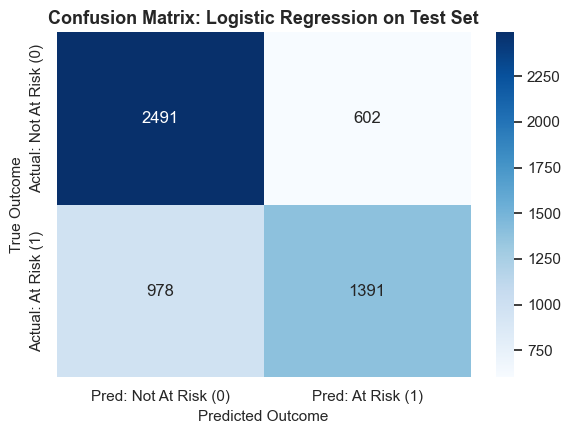

In [15]:
# Compute and visualize Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Pred: Not At Risk (0)', 'Pred: At Risk (1)'],
    yticklabels=['Actual: Not At Risk (0)', 'Actual: At Risk (1)']
)
plt.title('Confusion Matrix: Logistic Regression on Test Set', fontsize=13, fontweight='bold')
plt.ylabel('True Outcome', fontsize=11)
plt.xlabel('Predicted Outcome', fontsize=11)
plt.tight_layout()
plt.show()


In [16]:
# Summary of Test Set Performance Metrics
test_metrics_summary = pd.DataFrame({
    'Metric': ['Recall (At Risk)', 'Precision (At Risk)', 'F1-Score', 'ROC-AUC', 'PR-AUC'],
    'Training CV Mean': [
        cv_comparison.loc[cv_comparison['Model'] == 'Logistic Regression', 'Recall'].values[0],
        cv_comparison.loc[cv_comparison['Model'] == 'Logistic Regression', 'Precision'].values[0],
        cv_comparison.loc[cv_comparison['Model'] == 'Logistic Regression', 'F1-Score'].values[0],
        cv_comparison.loc[cv_comparison['Model'] == 'Logistic Regression', 'ROC-AUC'].values[0],
        cv_comparison.loc[cv_comparison['Model'] == 'Logistic Regression', 'PR-AUC'].values[0]
    ],
    'Test Set Score': [
        recall_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_proba),
        average_precision_score(y_test, y_test_proba)
    ]
})

test_metrics_summary['Difference'] = (test_metrics_summary['Test Set Score'] - test_metrics_summary['Training CV Mean']).round(4)
test_metrics_summary.round(4)


,Metric,Training CV Mean,Test Set Score,Difference
0,Recall (At Risk),0.5856,0.5872,0.0015
1,Precision (At Risk),0.7041,0.6979,-0.0062
2,F1-Score,0.6394,0.6378,-0.0016
3,ROC-AUC,0.7717,0.7745,0.0028
4,PR-AUC,0.7479,0.7413,-0.0066
